# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name: Sadia Fatima**
**Student ID:023-24-2013**
**Section:G**
**GitHub:https://github.com/Sadia-Farooque/Machine_Learning.git**
**Kaggle:https://www.kaggle.com/anamfarooque**
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [16]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [17]:
# Task 1 — load spam.csv, inspect shape/head/class balance
df = pd.read_csv("spam.csv", encoding="latin-1")
# df.info()
# print(df.shape)
# print(df.head(10))

spam_df = df[["v1","v2"]].copy()
spam_df.columns = ["label", "text"]
print(spam_df.shape)
print(spam_df.head(10))

counts = spam_df["label"].value_counts()
percents = spam_df["label"].value_counts(normalize=True) * 100

spam_balance = pd.DataFrame({"Count": counts, "Percentage (%)": percents.round(2)})
spam_balance

(5572, 2)
  label                                               text
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
5  spam  FreeMsg Hey there darling it's been 3 week's n...
6   ham  Even my brother is not like to speak with me. ...
7   ham  As per your request 'Melle Melle (Oru Minnamin...
8  spam  WINNER!! As a valued network customer you have...
9  spam  Had your mobile 11 months or more? U R entitle...


,Count,Percentage (%)
label,,
ham,4825,86.59
spam,747,13.41


one row is one SMS message with its ham/spam label. 
5,572 SMS messages,data is imbalanced, About 87% of messages are ham

In [18]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
df2= pd.read_csv("Tweets.csv")
# df2.info()
# print(df2.shape)
# print(df2.head(10))

counts = df2["airline_sentiment"].value_counts()
percents = df2["airline_sentiment"].value_counts(normalize=True) * 100

pd.DataFrame({"Count": counts, "Percentage (%)": percents.round(2)}) 

tweets_df = df2[df2["airline_sentiment"] != "neutral"]
tweets_df = tweets_df[["airline_sentiment", "text"]].reset_index(drop=True)   # tweets_df, not df2

print("Rows after dropping neutral:", len(tweets_df))                         # tweets_df


counts = tweets_df["airline_sentiment"].value_counts()                         # tweets_df
percents = tweets_df["airline_sentiment"].value_counts(normalize=True) * 100
display(pd.DataFrame({"Count": counts, "Percentage (%)": percents.round(2)}))

Rows after dropping neutral: 11541


,Count,Percentage (%)
airline_sentiment,,
negative,9178,79.53
positive,2363,20.47


 one row is one tweet about a US airline with its sentiment label.the oriinal smaples were around 14k , now after dropping the nrutral column , they are upto 11k , and the class usre is imbalance as 80 percent of the data has a label postive 

**Answer 2 (Task A — spam):**
messaging system receives a new SMS and must decide in real time whether to deliver it to the inbox or move it to a spam folder. Two possible labels, spam or ham, make it binary.
**Answer 2 (Task B — sentiment):**
an airline receives thousands of tweets a day. A model could automatically flag negative ones so the customer-service team responds to unhappy customers quickly, or so the airline can track satisfaction over time. It's binary because we deliberately kept only positive and negative. Neutral is a real third category, but the lab drops it to keep the problem two-class.
so in the tweets dataset we got 3099 neutal counts , which makes 21.17 percent of our dataset after removal we will get 11541 smaples from 14k samples .


---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [19]:
# Task 3 — clean text
import re 

def clean_text (text):
    text =text.lower()
    text = re.sub(r"[^\w\s]", " ", text)    
    text = re.sub(r"\s+", " ", text)         
    return text.strip()


spam_df ["clean_text"] = spam_df["text"].apply(clean_text)
spam_df[["text","clean_text"]].head(10)

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it s been 3 week s n...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more u r entitled...


lowercsing merges CAt to cat as one feature , and removing ectra notation/puncttuations stops confusuing in winner!! and winner and will count as same words 

In [20]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
spam_df["label_num"] = spam_df["label"].map({"ham": 0, "spam": 1})
spam_df["label_num"].value_counts()

X = spam_df["clean_text"]
y = spam_df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))
print("Spam % in train:", round(y_train.mean() * 100, 2))
print("Spam % in test:", round(y_test.mean() * 100, 2))

vectorizer = TfidfVectorizer()

X_train_vec = vectorizer.fit_transform(X_train)   # learn vocabulary + IDF from train only
X_test_vec  = vectorizer.transform(X_test)        # apply the same vocabulary to test

print("Vocabulary size (features):", len(vectorizer.get_feature_names_out()))
print("X_train_vec shape:", X_train_vec.shape)
print("X_test_vec shape:", X_test_vec.shape)

Train size: 4457
Test size: 1115
Spam % in train: 13.42
Spam % in test: 13.36
Vocabulary size (features): 7701
X_train_vec shape: (4457, 7701)
X_test_vec shape: (1115, 7701)


**Answer 4 (why fit on training data only):**
After a stratified 80/20 split (4,457 train and 1,115 test messages, both about 13.4% spam), the TF-IDF vectorizer learned 7,701 unique words from the training data, so every message is now a row of 7,701 word weights. I fit the vectorizer on the training set only because fitting on all the data would let the test messages shape the vocabulary and word weights, leaking information into training and making the results look better than they would on genuinely new messages.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

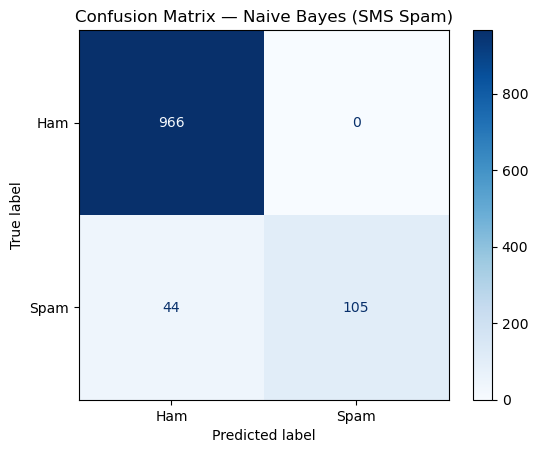

[[966   0]
 [ 44 105]]


In [21]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
nb_model = MultinomialNB()
nb_model.fit(X_train_vec, y_train)

y_pred = nb_model.predict(X_test_vec)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)

nb_spam_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [acc, prec, rec, f1]
}).round(4)

nb_spam_results


cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Ham", "Spam"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Naive Bayes (SMS Spam)")
plt.show()

print(cm)

so my confusuion matic shows that my model let some spam messgaes into the inbox as the main reason are the 87 % of the ham labeeled present 

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy |0.96 |
| Precision |1.00 |
| Recall | 0.704|
| F1-score | 0.826 |

**Answer 6:**
for SMS spam filtering, I think a false negative is the worse mistake, because a lot of SMS spam isn't harmless advertising but scams and phishing links (fake prize claims, fake bank alerts), and people tend to trust and act on text messages quickly. A real message wrongly sent to the spam folder is annoying, but the user can still find and recover it, whereas money or passwords lost to a scam that reached the inbox usually can't be recovered. For this reason, I would prioritize recall if I had to tune the model further. My model's perfect precision (0 false positives) looks impressive, but its recall of only 0.70 means 44 out of 149 spam messages still reached the inbox, and that is the weakness I would work on reducing first.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [22]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_

feature_names = vectorizer.get_feature_names_out()

log_prob_ham  = nb_model.feature_log_prob_[0]
log_prob_spam = nb_model.feature_log_prob_[1]


log_diff = log_prob_spam - log_prob_ham

top_spam_idx = np.argsort(log_diff)[::-1][:15]  
top_ham_idx  = np.argsort(log_diff)[:15]        

top_words = pd.DataFrame({
    "Top Spam Words": feature_names[top_spam_idx],
    "Spam Score": log_diff[top_spam_idx].round(3),
    "Top Ham Words": feature_names[top_ham_idx],
    "Ham Score": log_diff[top_ham_idx].round(3)
})

top_words

,Top Spam Words,Spam Score,Top Ham Words,Ham Score
0,claim,3.468,gt,-3.207
1,prize,3.265,lt,-3.196
2,150p,3.002,my,-3.175
3,www,2.999,ok,-3.136
4,uk,2.899,ll,-3.097
5,tone,2.862,later,-3.030
6,18,2.806,lor,-2.971
7,guaranteed,2.787,da,-2.933
8,cs,2.750,but,-2.863
9,1000,2.729,home,-2.859


**Answer 7:**
The top spam words match my intuition about spam very closely. Words like claim, prize, guaranteed, awarded, 1000, 500, and 150p are exactly the language of fake reward and prize scams, while www, uk, landline, tone, and cs come from the links, premium-rate phone numbers, and "customer service" terms that spam messages use to get people to respond. The ham words look like everyday personal texting: ok, later, home, sorry, come, my, and how, plus informal slang like lor and da, which shows the model learned that casual, conversational messages are usually real. 

In [23]:
# Task 8 — test your own messages
my_messages = [
    "Congratulations! You have won a FREE prize worth 1000 cash. Call 09061234567 now to claim!",
    "Hey, are we still meeting for lunch tomorrow? Let me know",
    "Your account has been selected for a reward, reply YES to claim"
]


my_clean = [clean_text(msg) for msg in my_messages]
my_vec = vectorizer.transform(my_clean)

my_preds = nb_model.predict(my_vec)
my_probs = nb_model.predict_proba(my_vec)[:, 1]   

pd.DataFrame({
    "Message": my_messages,
    "Prediction": ["Spam" if p == 1 else "Ham" for p in my_preds],
    "Spam Probability": my_probs.round(3)
})

,Message,Prediction,Spam Probability
0,Congratulations! You have won a FREE prize wor...,Spam,0.965
1,"Hey, are we still meeting for lunch tomorrow? ...",Ham,0.000
2,"Your account has been selected for a reward, r...",Spam,0.645


**Answer 8:**
On my run, the model predicted all three messages as expected: the obvious prize message was classified as spam with about 96% confidence, the lunch message as ham with almost 0% spam probability, and the "reward" message as spam. However, the third message only reached about 65% spam probability, even though it is clearly a scam. This is because it avoids the model's strongest spam signals (no link, no phone number, no "prize" or "free") and relies on words like "account" and "reply" that also appear in normal messages. This shows that a scammer who uses more ordinary wording could slip past a Naive Bayes filter that depends heavily on specific keywords.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
https://www.kaggle.com/code/anamfarooque/notebookad92363867/edit?inquiry-id=inq_A7UTz9k8wuwoymkf6VKA9swYTp1a24&reference-id=32005763&subject=32005763&status=completed&fields%5Bcurrent-selfie%5D%5Btype%5D=selfie&fields%5Bcurrent-selfie%5D%5Bvalue%5D%5Bid%5D=self_A7UTz9k1TRxbHeGuQdLVrLqhKYrfAh&fields%5Bcurrent-selfie%5D%5Bvalue%5D%5Btype%5D=Selfie%3A%3AProfileAndCenter&fields%5Bhashed-identification-number%5D%5Btype%5D=string&fields%5Bhashed-identification-number%5D%5Bvalue%5D=

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [24]:
# Task 11 — clean and vectorize the tweets
def clean_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)   # remove URLs
    text = re.sub(r"@\w+", " ", text)             # remove @mentions (airline handles)
    text = re.sub(r"&\w+;", " ", text)            # remove HTML entities like &amp;
    text = re.sub(r"#", " ", text)                # drop the # but keep the hashtag word
    text = re.sub(r"[^\w\s]", " ", text)          # remove remaining punctuation
    text = re.sub(r"\s+", " ", text)              # collapse extra spaces
    return text.strip()

tweets_df["clean_text"] = tweets_df["text"].apply(clean_tweet)

tweets_df[["text", "clean_text"]].head(10)

tweets_df["label_num"] = tweets_df["airline_sentiment"].map({"negative": 0, "positive": 1})

X_t = tweets_df["clean_text"]
y_t = tweets_df["label_num"]

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_t, y_t, test_size=0.2, random_state=42, stratify=y_t
)

print("Train size:", len(X_train_t))
print("Test size:", len(X_test_t))
print("Positive % in train:", round(y_train_t.mean() * 100, 2))
print("Positive % in test:", round(y_test_t.mean() * 100, 2))

# Same fit-on-train-only discipline as Task A
vectorizer_t = TfidfVectorizer()
X_train_vec_t = vectorizer_t.fit_transform(X_train_t)
X_test_vec_t  = vectorizer_t.transform(X_test_t)

print("Vocabulary size (features):", len(vectorizer_t.get_feature_names_out()))
print("X_train_vec_t shape:", X_train_vec_t.shape)
print("X_test_vec_t shape:", X_test_vec_t.shape)

Train size: 9232
Test size: 2309
Positive % in train: 20.47
Positive % in test: 20.49
Vocabulary size (features): 10078
X_train_vec_t shape: (9232, 10078)
X_test_vec_t shape: (2309, 10078)


**Answer 12:**
Beyond the lowercasing and punctuation removal I did for the SMS messages, I also stripped @mentions, URLs and HTML entities from the tweets, and removed the # symbol while keeping the hashtag word. Tweets need this because almost every one of them tags an airline handle and many include a unique shortened link, so these tokens carry no sentiment information and only inflate the vocabulary, whereas #fail and fail mean the same thing and should count as a single feature.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

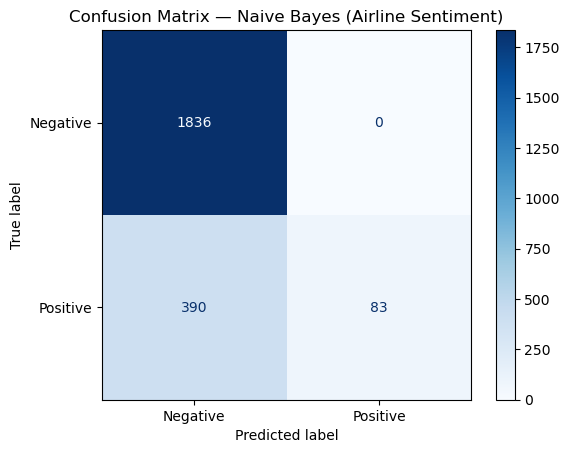

[[1836    0]
 [ 390   83]]


In [25]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix

nb_model_t = MultinomialNB()
nb_model_t.fit(X_train_vec_t, y_train_t)

y_pred_t = nb_model_t.predict(X_test_vec_t)

acc_t  = accuracy_score(y_test_t, y_pred_t)
prec_t = precision_score(y_test_t, y_pred_t)
rec_t  = recall_score(y_test_t, y_pred_t)
f1_t   = f1_score(y_test_t, y_pred_t)

nb_tweet_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [acc_t, prec_t, rec_t, f1_t]
}).round(4)

nb_tweet_results

cm_t = confusion_matrix(y_test_t, y_pred_t)

disp_t = ConfusionMatrixDisplay(confusion_matrix=cm_t, display_labels=["Negative", "Positive"])
disp_t.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Naive Bayes (Airline Sentiment)")
plt.show()

print(cm_t)

Naive Bayes reached 83% accuracy on the airline tweets, but the other metrics show this number is misleading. Precision for the positive class is 1.00 while recall is only 0.175, giving an F1 of just 0.29: of the 473 genuinely positive tweets in the test set, the model correctly identified only 83 and misclassified 390 as negative. Since 79.5% of the tweets are negative, a model that simply predicted "negative" every time would already score 79.5% accuracy, so the model's real skill over that baseline is very small. The heavy class imbalance pushes the prior strongly toward the negative class, and the positive-word evidence in a short tweet is rarely strong enough to overcome it, which is exactly why accuracy alone is a poor metric for this task.

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy |0.83 |
| Precision |1 |
| Recall | 0.175|
| F1-score |0.29 |

**Answer 14:**
Naive Bayes performed clearly worse on sentiment than on spam. Although the headline accuracy dropped only from 96% to 83%, the F1-score collapsed from 0.83 to 0.29, and the model beat the majority-class baseline by just 3.5 points on the tweets compared with roughly 10 points on the SMS data. The "naive" independence assumption is a much better fit for spam because spam is formulaic and keyword-driven: words like claim, prize, guaranteed and 150p are almost decisive on their own, so treating each word as independent evidence loses very little information. Sentiment works the opposite way, since meaning comes from how words combine rather than from individual words: "not good" and "good" share the same sentiment word but mean opposites, and a sarcastic tweet like "great, another 3 hour delay, thanks" is full of positive words while being clearly negative. Because the model sees only isolated unigrams, it cannot link not to the word it modifies, and my confusion matrix reflects this directly  390 of 473 positive tweets were misread as negative, which is consistent with positive tweets that contain complaint vocabulary ("no delays", "finally on time") being pulled toward the negative class by their individual words.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
https://www.kaggle.com/code/anamfarooque/notebooke7853349c9/edit

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

In [26]:

comparison_tasks = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Task A — Spam": [acc, prec, rec, f1],
    "Task B — Sentiment": [acc_t, prec_t, rec_t, f1_t]
}).round(4)

comparison_tasks

,Metric,Task A — Spam,Task B — Sentiment
0,Accuracy,0.9605,0.8311
1,Precision,1.0000,1.0000
2,Recall,0.7047,0.1755
3,F1-score,0.8268,0.2986


**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | 0.96|0.83 |
| Precision |1 | 1|
| Recall | 0.7| 0.17|
| F1-score | 0.82| 0.29|

Naive Bayes performed far better on spam detection than on sentiment. Both models share the same conservative pattern of perfect precision with no false positives, but the recall gap is enormous: 0.70 on spam versus 0.175 on sentiment. Measured against the majority-class baselines (86.6% for spam, 79.5% for tweets), the spam model gains about 10 accuracy points while the sentiment model gains only about 3.5, so the F1 difference of 0.83 versus 0.29 is the fairest summary of how much better suited Naive Bayes was to the spam task.

In [27]:
# Task 18 — train Logistic Regression on Task A's vectorized features

from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_vec, y_train)          # exact same TF-IDF features as Naive Bayes

y_pred_lr = logreg.predict(X_test_vec)

comparison_models = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Naive Bayes": [acc, prec, rec, f1],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr)
    ]
}).round(4)

comparison_models

,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.9605,0.9722
1,Precision,1.0000,0.9917
2,Recall,0.7047,0.7987
3,F1-score,0.8268,0.8848


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy |0.9605 |0.9722 |
| Precision | 1| 0.9917|
| Recall | 0.7047| 0.7987|
| F1-score |0.8268	 | 0.8848|

**Answer 18 (which wins, and does it match expectations):**
Trained on exactly the same TF-IDF features, Logistic Regression beat Naive Bayes on F1 by a clear margin (0.8848 vs. 0.8268), mainly by raising recall from 0.705 to 0.799 while giving up almost no precision (0.9917 vs. a perfect 1.00). This matches what I would expect from theory: Logistic Regression makes no independence assumption and learns all its word weights jointly, so it can discount correlated spam words like "free", "prize" and "claim" that tend to appear together, whereas Naive Bayes treats each as separate independent evidence and effectively double-counts them. The gap is real but not huge, which fits the argument from Task 14 that spam is formulaic and keyword-driven, so the naive assumption costs relatively little here compared with sentiment. The recall gain matters most for this application, since in Task 6 I argued that recall is the metric worth prioritizing for a spam filter Logistic Regression catches roughly 14 more spam messages out of 149 at the cost of a single false positive.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes was clearly better suited to spam detection than to sentiment analysis: it reached an F1 of 0.83 on the SMS data but only 0.29 on the airline tweets, gaining about 10 accuracy points over the majority-class baseline in the first task versus barely 3.5 in the second. The reason is that spam is formulaic and keyword-driven, so treating words as independent evidence loses very little, whereas sentiment depends on how words combine. What surprised me most in the Part 4 word interpretation was that alongside the expected spam words like claim, prize and guaranteed the model happily learns dataset artifacts if they happen to correlate with a class. On the same TF-IDF features, Logistic Regression outperformed Naive Bayes (F1 0.8848 vs. 0.8268), lifting recall from 0.705 to 0.799 while losing almost no precision, which matches the theory that a model learning its weights jointly can handle correlated words that Naive Bayes double-counts. The independence limitation I observed most directly was in Task B, where 390 of 473 positive tweets were misclassified as negative: because the model sees only isolated unigrams, it cannot connect not to the word it modifies, so phrases like "no delays" or "not bad" get pulled toward the negative class by their individual words. Overall, Naive Bayes remains a fast, interpretable baseline that is genuinely competitive on keyword-driven text, but it is the wrong tool when meaning depends on context. Compared with the four tabular classifiers from Labs 3–6, its real advantage is how effortlessly it scales to thousands of sparse word features.

**Answer 20 — Kaggle Notebook Links:**
- Task A: https://www.kaggle.com/code/anamfarooque/notebookad92363867/edit?inquiry-id=inq_A7UTz9k8wuwoymkf6VKA9swYTp1a24&reference-id=32005763&subject=32005763&status=completed&fields%5Bcurrent-selfie%5D%5Btype%5D=selfie&fields%5Bcurrent-selfie%5D%5Bvalue%5D%5Bid%5D=self_A7UTz9k1TRxbHeGuQdLVrLqhKYrfAh&fields%5Bcurrent-selfie%5D%5Bvalue%5D%5Btype%5D=Selfie%3A%3AProfileAndCenter&fields%5Bhashed-identification-number%5D%5Btype%5D=string&fields%5Bhashed-identification-number%5D%5Bvalue%5D=
- Task B: https://www.kaggle.com/code/anamfarooque/notebooke7853349c9/edit

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted